# Paris air quality forecasting — X-HEC Time Series challenge

**Author:** Martino Orioli · **Course:** X-HEC MSc, Time Series (Capgemini)

**Task.** Forecast hourly concentrations of CO, NO₂, O₃, PM10 and PM2.5 in Paris for the 504 hours
(3 weeks) after the end of the training data, and compare simple baselines with a zero-shot
time-series foundation model (Chronos-2).

**What this notebook does**, in the order of the assignment:
1. Data understanding and preparation
2. Validation strategy and baselines (persistence, seasonal naive 168 h)
3. Zero-shot Chronos-2 forecasting
4. Comparative experiments: independent vs joint, foundation model vs LSTM
5. One targeted fix for the September level shift
6. Results and discussion
7. Final forecast and submission

The modelling code lives in `src/` and is unit-tested in `tests/` (metrics at y = 0, no-leakage
checks on every feature and validation split). This notebook calls it instead of re-implementing it.

**How to run.** Locally: open from the project folder and run all cells. In Google Colab: copy the
whole project folder (including `data/raw/`) to Google Drive, open this notebook from there, set
`DRIVE_PROJECT_DIR` in the next cell if your path differs, choose a GPU runtime, then run all.

In [3]:
# --- Setup: environment, paths, seeds -------------------------------------------------------
import os, sys, subprocess, random, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/Colab_Notebooks/class_time_serie"  # edit if you copied it elsewhere

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "chronos-forecasting==2.3.2", "holidays>=0.40"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(DRIVE_PROJECT_DIR)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (PROJECT_DIR / "src").exists(), f"src/ not found under {PROJECT_DIR}"
assert (PROJECT_DIR / "data" / "raw" / "train.csv").exists(), "put the Kaggle files in data/raw/"
sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)

import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from data import load_raw, audit, make_submission
from metrics import TARGETS
from evaluation import (make_windows, run_model, mae_table, summarize, score,
                        mae_by_horizon_block, log_results)
from models import LastValue, SeasonalNaive, SeasonalMean
from foundation import Chronos2Forecaster, load_pipeline, run_info
from adjust import SeasonallyAdjusted, seasonal_ratios, adjustment_factors
from lstm import LSTMForecaster
import plots

SHORT = {c: c.replace("valeur_", "") for c in TARGETS}
print("project:", PROJECT_DIR, "| Colab:", IN_COLAB, "| torch", torch.__version__,
      "| CUDA:", torch.cuda.is_available(), "| MPS:", torch.backends.mps.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project: /content/drive/MyDrive/Colab_Notebooks/class_time_serie | Colab: True | torch 2.11.0+cu130 | CUDA: True | MPS: False


## 1. Data understanding and preparation

### 1.1 Load and check the structure

In [4]:
raw = load_raw()
train, test, sample = raw["train"], raw["test"], raw["sample_submission"]
print("train columns:", list(train.columns))
print("test columns: ", list(test.columns))
print("timestamp column: 'id' (string 'YYYY-MM-DD HH', CET) -> parsed into 'datetime'")
print("pollutant columns:", TARGETS)
display(train.head(3))

for name, d in [("train", train), ("test", test)]:
    t = d["datetime"]
    full = pd.date_range(t.min(), t.max(), freq="h")
    print(f"{name:5s}: {len(d):6d} rows  {t.min()} -> {t.max()} | sorted: {t.is_monotonic_increasing} "
          f"| duplicate timestamps: {t.duplicated().sum()} | missing hours in index: {len(full.difference(t))}")
print("gap between train end and test start:", test.datetime.min() - train.datetime.max())
print("test ids identical to sample_submission ids:", test["id"].equals(sample["id"]))

train columns: ['id', 'valeur_NO2', 'valeur_CO', 'valeur_O3', 'valeur_PM10', 'valeur_PM25', 'datetime']
test columns:  ['id', 'datetime']
timestamp column: 'id' (string 'YYYY-MM-DD HH', CET) -> parsed into 'datetime'
pollutant columns: ['valeur_CO', 'valeur_NO2', 'valeur_O3', 'valeur_PM10', 'valeur_PM25']


,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,datetime
0,2020-01-01 00,42.9,0.718,15.7,73.1,64.4,2020-01-01 00:00:00
1,2020-01-01 01,33.6,0.587,10.1,74.8,66.0,2020-01-01 01:00:00
2,2020-01-01 02,29.3,NaN,5.1,51.0,44.9,2020-01-01 02:00:00


train:  40991 rows  2020-01-01 00:00:00 -> 2024-09-03 22:00:00 | sorted: True | duplicate timestamps: 0 | missing hours in index: 0
test :    504 rows  2024-09-03 23:00:00 -> 2024-09-24 22:00:00 | sorted: True | duplicate timestamps: 0 | missing hours in index: 0
gap between train end and test start: 0 days 01:00:00
test ids identical to sample_submission ids: True


The index is clean: hourly, sorted, no duplicated and no missing timestamps, and the test block
(504 h) starts exactly one hour after the last training row. Missingness is in the **values**, not
in the timestamps.

### 1.2 Data quality per pollutant

In [5]:
info = audit(train, test)
q = info["per_target"].rename(index=SHORT)
display(q.round(3))

,missing_pct,zeros,negatives,min,median,max,mean,std
CO,30.57,0.0,0.0,0.037,0.177,4.309,0.201,0.104
NO2,8.04,0.0,0.0,1.100,17.600,131.000,21.832,14.658
O3,1.69,84.0,10.0,-1.900,50.700,193.100,50.574,26.489
PM10,17.48,0.0,0.0,0.500,15.600,128.500,18.222,11.282
PM25,4.37,9.0,0.0,0.000,8.700,111.100,11.051,8.152


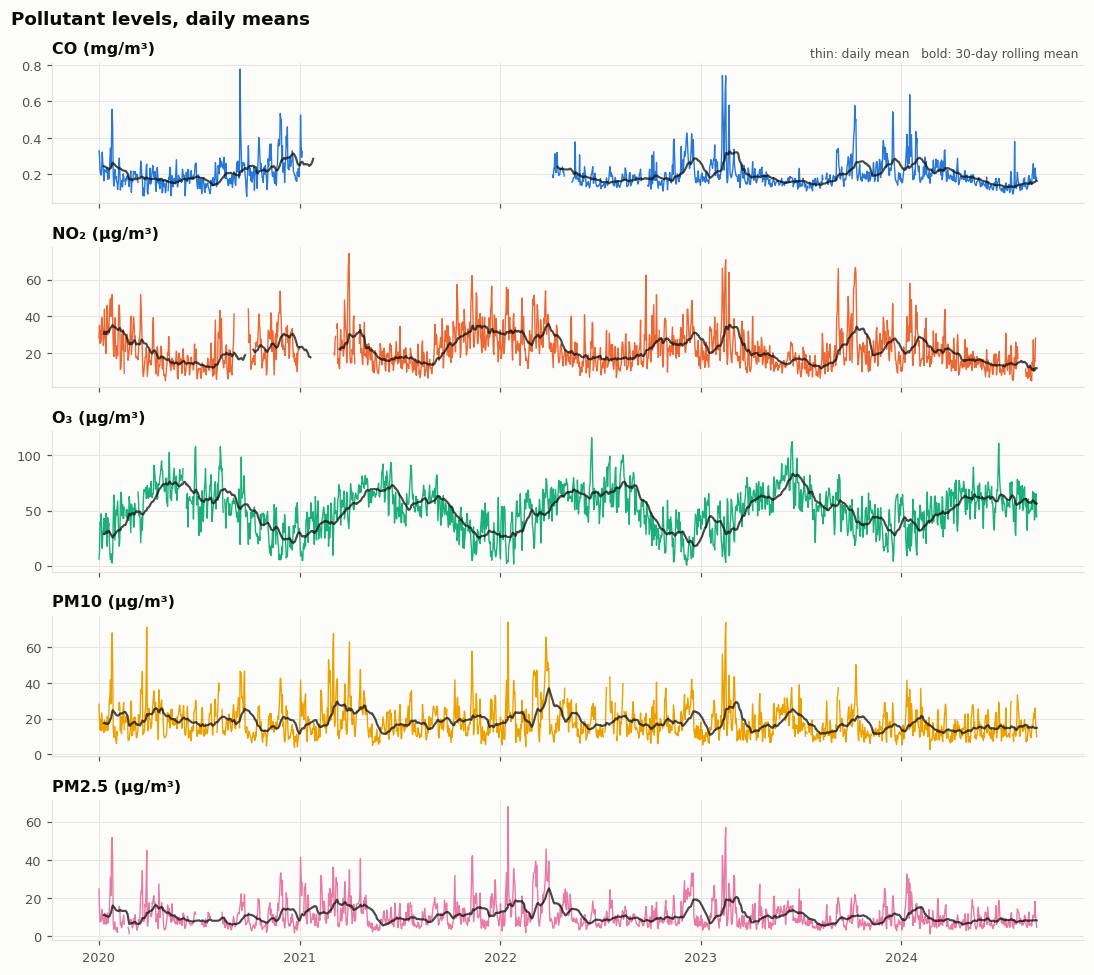

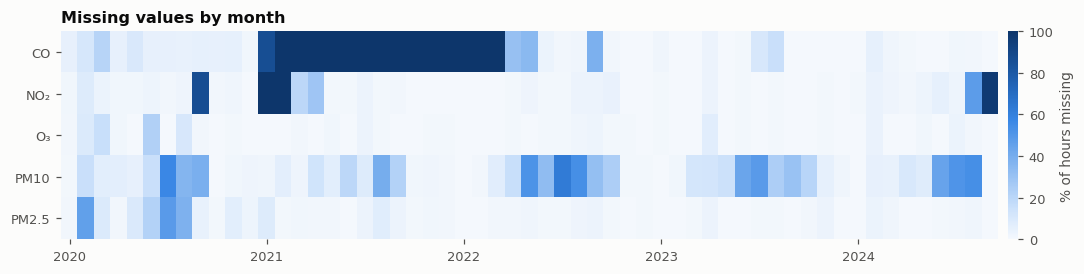

In [6]:
_ = plots.series_overview(train)
_ = plots.missingness_heatmap(train)

**Quality findings**
- **CO is missing for most of 2021 and early 2022** (a sensor outage of more than a year) and
  ~31 % overall. **PM10** is missing ~18 % of hours, in scattered blocks.
- **NO₂ has an outage right before the forecast origin** (see 1.4): its last observed value is
  69 h before the test period starts.
- **O₃ has zeros and a few small negative values** (sensor noise around 0). That is why plain
  MAPE is never used here, and why final predictions are clipped at 0.
- Episodes (winter particle peaks, CO spikes) reach several times the 99th percentile. They
  dominate squared errors but matter less under MAE.

### 1.3 Patterns: daily, weekly, yearly, and between pollutants

,CO,NO2,O3,PM10,PM25
lag 24 h,0.47,0.54,0.71,0.52,0.56
lag 168 h,0.22,0.35,0.53,0.17,0.15
lag 336 h,0.19,0.35,0.52,0.10,0.09


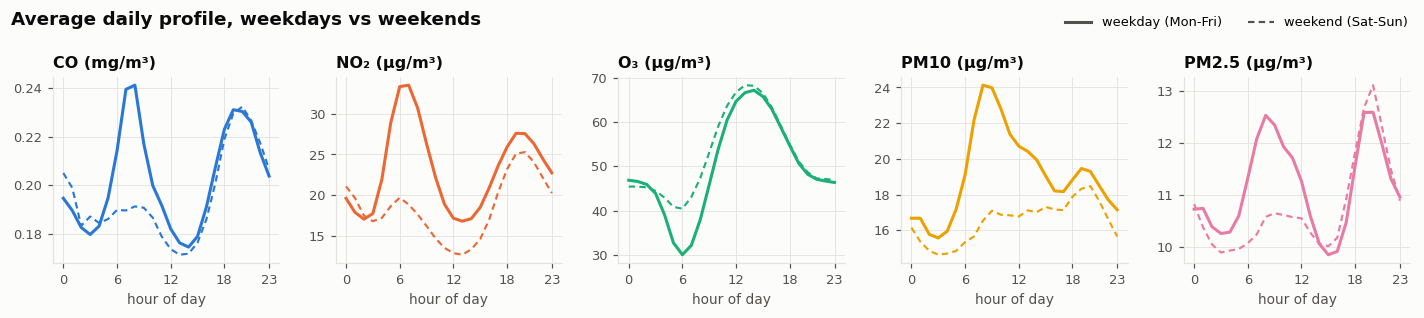

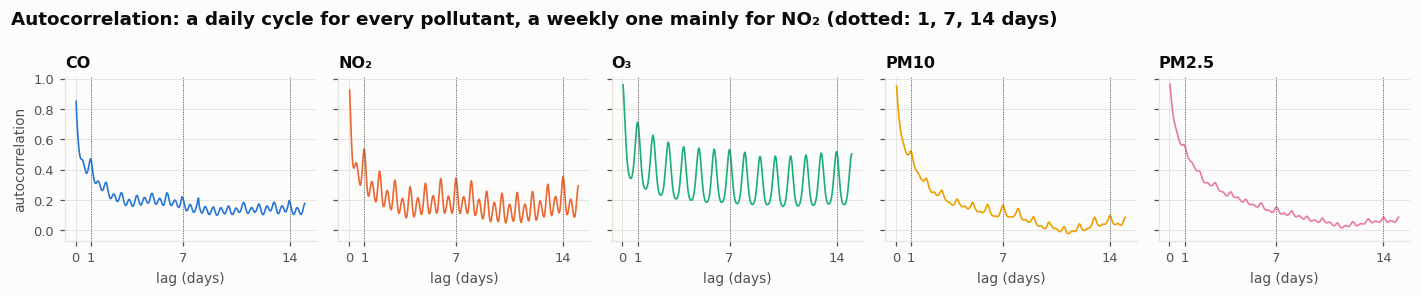

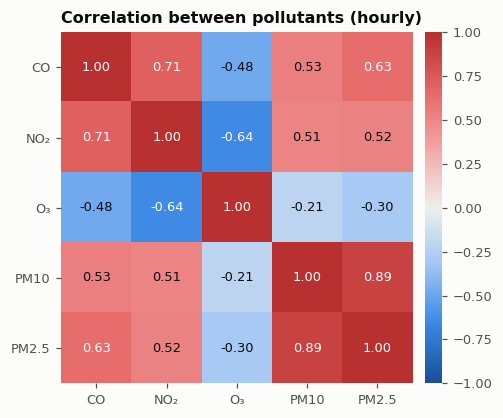

In [7]:
_ = plots.daily_weekly_profiles(train)
_ = plots.autocorrelation(train)
_ = plots.correlation_matrix(train)
acf = pd.DataFrame({SHORT[c]: [train[c].autocorr(k) for k in (24, 168, 336)] for c in TARGETS},
                   index=["lag 24 h", "lag 168 h", "lag 336 h"]).round(2)
display(acf)

**What the plots show**
- **Hourly / daily:** every pollutant has a strong 24 h cycle (ACF peaks at 1, 2, 3 … days).
  NO₂ and CO show the traffic signature: morning (7–9 h) and evening (18–21 h) rush-hour peaks.
  O₃ is the mirror image: it is produced by sunlight and destroyed by NO, so it peaks in the
  early afternoon and dips at the morning rush.
- **Weekly:** the weekday/weekend gap is large for NO₂, CO and PM10 (no morning rush at weekends).
  In the ACF, NO₂ and O₃ keep the same correlation at 168 h and 336 h, the sign of a stable
  weekly component. For PM10/PM2.5 the ACF decays steadily: particles follow weather episodes
  more than the calendar.
- **Yearly:** O₃ peaks in summer; NO₂, CO and particles are higher in winter (heating, inversions).
- **Between pollutants:** NO₂ and CO move together (traffic); PM10 and PM2.5 are strongly
  correlated (PM2.5 is a subset of PM10); O₃ is negatively correlated with NO₂.

### 1.4 The test period: gaps and distribution shift

forecast origin 2024-09-03 23:00:00; NO2 last observed 2024-09-01 01:00:00 (70 h before the origin)


**Ratio of the mean level in Sep 4–24 to the 3 weeks before, by year:**

,CO,NO2,O3,PM10,PM25
2020,1.37,NaN,1.07,1.77,2.05
2021,NaN,1.81,0.92,1.04,1.13
2022,1.01,1.30,0.75,0.77,0.81
2023,1.29,1.76,0.99,1.13,1.40


**Mean level in the 3 weeks before the test origin (2024):**

,CO,NO2,O3,PM10,PM25
2024,0.17,10.61,52.63,14.91,8.49


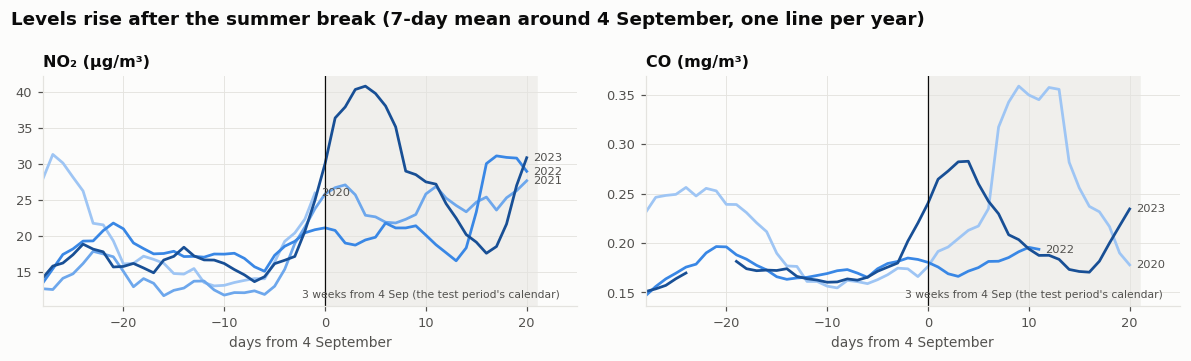

In [8]:
T = TARGETS
origin = test.datetime.min()
last_no2 = train.loc[train.valeur_NO2.last_valid_index(), "datetime"]
print(f"forecast origin {origin}; NO2 last observed {last_no2} "
      f"({(origin - last_no2) / pd.Timedelta(hours=1):.0f} h before the origin)")

# Level in the 3 weeks after 4 Sep vs the 3 weeks before, in earlier years
rows = {}
for y in range(2020, 2024):
    o = pd.Timestamp(f"{y}-09-03 23:00")
    b = train[(train.datetime >= o - pd.Timedelta(hours=504)) & (train.datetime < o)][T].mean()
    a = train[(train.datetime >= o) & (train.datetime < o + pd.Timedelta(hours=504))][T].mean()
    rows[y] = (a / b)
display(Markdown("**Ratio of the mean level in Sep 4–24 to the 3 weeks before, by year:**"))
display(pd.DataFrame(rows).T.rename(columns=SHORT).round(2))
recent = train[train.datetime >= origin - pd.Timedelta(hours=504)][T].mean().rename(SHORT)
display(Markdown("**Mean level in the 3 weeks before the test origin (2024):**"))
display(recent.round(2).to_frame("2024").T)
_ = plots.september_rebound(train)

**Distribution shift.** The test period (4–24 September 2024) follows the August holidays. In
every year with data, **NO₂ rises sharply after the summer break** (×1.3 to ×1.8), CO less so;
particles go either way depending on weather; O₃ does not rise. The rise starts ~3 days before
4 September (schools re-open) — exactly the hours where NO₂ is unobserved in 2024. Any model that
anchors on the recent level will **under-forecast NO₂ in the test period**. This motivates the
second validation window below.

### 1.5 Missing values: how they are handled
- **Never interpolated across time.** Interpolating a gap uses the value *after* the gap; inside a
  validation or test window that is the future we are trying to predict, so the score would be
  optimistic and the method impossible to run for real. Even inside the training history, a
  causal approach is used so the same code is valid at the forecast origin.
- **Missing truth is skipped in scoring** (per pollutant), never filled.
- **Per model:** persistence uses the last *observed* value; seasonal naive fills a hole in the
  copied week from the same hour 2, 3, … weeks earlier; Chronos-2 accepts NaN in its context
  natively; the LSTM gets 0 (= training mean after scaling) **plus a missingness flag**, and its
  loss ignores missing targets.

## 2. Validation strategy and baselines

**Why not a random split?** Neighbouring hours are strongly correlated, so a random split puts
hours from the same day into both train and validation: the model is evaluated on points it has
effectively seen, and it is allowed to use the future to predict the past. The real task is to
forecast a **whole block of 504 future hours from the past only**, so validation must do exactly
that.

**Windows.** Every window is a 504 h block; models only see rows strictly before its start.
- `primary` — the last 504 h of train (13 Aug → 3 Sep 2024). The assignment's main comparison.
- `sep2023` — the same calendar weeks one year earlier (3 → 24 Sep 2023). It reproduces the
  test period's season, including the post-holiday rebound. **The final model is chosen on this
  window.** To be transparent about timing: this was decided *after* the September under-forecast
  of Chronos-2 had been noticed on this window, but *before* the LSTM and the seasonal fix were scored.
- `fold_0 … fold_5` — six consecutive 504 h folds ending at `primary` (`fold_5` = `primary`),
  used to show how much scores vary from one 3-week period to the next.

In [9]:
windows = make_windows(train, n_rolling=6)
display(pd.DataFrame([{"window": k, "history ends": h.datetime.max(), "window start": w.datetime.min(),
                        "window end": w.datetime.max(), "hours": len(w),
                        **{f"scored {SHORT[c]}": int(w[c].notna().sum()) for c in TARGETS}}
                       for k, (h, w) in windows.items()]))

,window,history ends,window start,window end,hours,scored CO,scored NO2,scored O3,scored PM10,scored PM25
0,primary,2024-08-13 22:00:00,2024-08-13 23:00:00,2024-09-03 22:00:00,504,498,394,504,299,491
1,sep2023,2023-09-03 22:00:00,2023-09-03 23:00:00,2023-09-24 22:00:00,504,504,503,504,351,504
2,fold_0,2024-04-30 22:00:00,2024-04-30 23:00:00,2024-05-21 22:00:00,504,504,503,504,459,504
3,fold_1,2024-05-21 22:00:00,2024-05-21 23:00:00,2024-06-11 22:00:00,504,504,487,494,398,504
4,fold_2,2024-06-11 22:00:00,2024-06-11 23:00:00,2024-07-02 22:00:00,504,504,462,501,247,499
5,fold_3,2024-07-02 22:00:00,2024-07-02 23:00:00,2024-07-23 22:00:00,504,495,502,484,210,502
6,fold_4,2024-07-23 22:00:00,2024-07-23 23:00:00,2024-08-13 22:00:00,504,502,179,497,261,500
7,fold_5,2024-08-13 22:00:00,2024-08-13 23:00:00,2024-09-03 22:00:00,504,498,394,504,299,491


In [10]:
ALL_ROWS, PREDS = [], {}

def add(rows_preds, name=None):
    rows, preds = rows_preds
    ALL_ROWS.extend(rows)
    for w, p in preds.items():
        PREDS[(name or rows[0]["model"], w)] = p

add(run_model(lambda: LastValue(), windows, label="persistence"))
add(run_model(lambda: SeasonalNaive(168), windows))
add(run_model(lambda: SeasonalNaive(24), windows))
add(run_model(lambda: SeasonalMean(lookback_days=28), windows, label="weekly_profile_4w"))
BASELINES = ["persistence", "seasonal_naive_24h", "seasonal_naive_168h", "weekly_profile_4w"]
tab = mae_table(ALL_ROWS)
display(tab[tab.window.isin(["primary", "sep2023"])].round(3))
display(summarize(ALL_ROWS).round(3))

,model,window,CO,NO2,O3,PM10,PM25,avg_MAE
0,persistence,primary,0.046,7.429,16.160,5.622,4.237,6.699
1,persistence,sep2023,0.060,15.820,23.521,7.904,5.819,10.625
8,seasonal_naive_168h,primary,0.044,9.469,17.303,6.450,3.555,7.364
9,seasonal_naive_168h,sep2023,0.064,15.773,25.345,7.876,5.322,10.876
16,seasonal_naive_24h,primary,0.045,7.429,14.254,6.212,4.210,6.430
17,seasonal_naive_24h,sep2023,0.063,17.219,21.357,7.931,5.582,10.431
24,weekly_profile_4w,primary,0.052,8.605,14.991,6.278,3.382,6.662
25,weekly_profile_4w,sep2023,0.064,15.601,20.669,6.822,5.142,9.660


window,primary,sep2023,rolling_mean,rolling_std
model,,,,
persistence,6.699,10.625,7.484,1.233
seasonal_naive_168h,7.364,10.876,7.918,1.011
seasonal_naive_24h,6.430,10.431,7.525,1.381
weekly_profile_4w,6.662,9.660,6.448,0.550


**Baselines.** Persistence repeats the last observed value for all 504 hours. Seasonal naive
168 h copies the last observed week. Seasonal naive 24 h and the 4-week weekly profile (mean by
hour × weekday over the last 28 days, window fixed in advance) are extra references, used only
to explain the result below.

**Why a 168 h lag?** Hourly urban pollution is driven by human activity on a weekly calendar:
weekdays have rush hours, weekends do not (section 1.3). A 168 h lag is the shortest lag that
matches *both* the hour of day and the day of the week, so a Monday forecast is copied from a
Monday, not from a Sunday.

**But in practice it does not beat persistence on average MAE.** Copying one specific week also
copies that week's noise and episodes. Under MAE, a central forecast is rewarded; averaging four
weeks of the same hour × weekday profile keeps the weekly shape and removes most of the noise, and
it beats both. So the weekly *shape* is real; copying a single week is just a noisy estimate of it.

**Why MAE per pollutant, not only the average?** The pollutants are on very different scales:
CO is in mg/m³ (MAE ≈ 0.05) while O₃ is in µg/m³ (MAE ≈ 15). The average is dominated by O₃ and
NO₂, and CO is invisible in it. A model can be much better or worse on CO, or on PM2.5, without the
average moving. The best model also differs by pollutant.

## 3. Zero-shot forecasting with Chronos-2

**Foundation model.** Chronos-2 is a transformer pretrained on a very large and diverse collection
of time series (real and synthetic). It learns general forecasting skills (seasonality, trends,
level shifts, uncertainty) once, and is then applied to new series. A model trained only on this
dataset knows nothing except these 4.7 years of Paris data.

**Zero-shot** means the pretrained weights are used as-is: no training, no fine-tuning on Paris
data. At prediction time the model only reads a context window (here up to 8,192 hours of
history, strictly before the forecast origin) and outputs quantile forecasts for the next 504 h.

**Two modes, same model:**
- *independent*: each pollutant is passed as its own univariate series;
- *joint*: the five pollutants are passed as one multivariate target, and Chronos-2's group
  attention lets each forecast attend to the others' history.

In [11]:
pipe = load_pipeline()
RUN_INFO = run_info(pipe)
display(pd.Series(RUN_INFO, name="Chronos-2 run").to_frame())

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,Chronos-2 run
model,amazon/chronos-2
chronos_forecasting,2.3.2
torch,2.11.0+cu130
device,cuda:0
params_millions,119.5
context_length_max,8192
platform,Linux-6.6.122+-x86_64-with-glibc2.39
processor,x86_64
gpu,Tesla T4


In [12]:
add(run_model(lambda: Chronos2Forecaster(mode="independent"), windows))
add(run_model(lambda: Chronos2Forecaster(mode="joint"), windows))
CHRONOS = ["chronos2_independent", "chronos2_joint"]
tab = mae_table(ALL_ROWS)
display(tab[tab.window.isin(["primary", "sep2023"]) & tab.model.isin(BASELINES + CHRONOS)].round(3))
display(summarize(ALL_ROWS).loc[BASELINES + CHRONOS].round(3))

,model,window,CO,NO2,O3,PM10,PM25,avg_MAE
0,persistence,primary,0.046,7.429,16.160,5.622,4.237,6.699
1,persistence,sep2023,0.060,15.820,23.521,7.904,5.819,10.625
8,seasonal_naive_168h,primary,0.044,9.469,17.303,6.450,3.555,7.364
9,seasonal_naive_168h,sep2023,0.064,15.773,25.345,7.876,5.322,10.876
16,seasonal_naive_24h,primary,0.045,7.429,14.254,6.212,4.210,6.430
17,seasonal_naive_24h,sep2023,0.063,17.219,21.357,7.931,5.582,10.431
24,weekly_profile_4w,primary,0.052,8.605,14.991,6.278,3.382,6.662
25,weekly_profile_4w,sep2023,0.064,15.601,20.669,6.822,5.142,9.660
32,chronos2_independent,primary,0.048,7.714,12.916,5.418,3.260,5.871
33,chronos2_independent,sep2023,0.062,15.845,18.093,6.782,5.095,9.175


window,primary,sep2023,rolling_mean,rolling_std
model,,,,
persistence,6.699,10.625,7.484,1.233
seasonal_naive_24h,6.430,10.431,7.525,1.381
seasonal_naive_168h,7.364,10.876,7.918,1.011
weekly_profile_4w,6.662,9.660,6.448,0.550
chronos2_independent,5.871,9.175,5.936,0.408
chronos2_joint,5.568,9.196,5.875,0.828


**Settings recorded above:** model `amazon/chronos-2`, `chronos-forecasting` version, device,
max context 8,192 h, prediction length 504 (emitted in one pass: the model outputs up to 1,024
steps directly, no autoregressive roll-out), quantiles 0.1/0.5/0.9, point forecast = **median**.

**Why the median when the metric is MAE?** For any predictive distribution, the value that
minimises the expected absolute error is its median (the mean minimises squared error). So the
0.5 quantile is the MAE-optimal point forecast. It is also robust: pollution distributions are
right-skewed with episodes, which pull the mean up but barely move the median.

## 4. Comparative experiments

### 4.1 Independent vs joint (Chronos-2)
The two Chronos-2 rows above use the same model, context and windows; only the grouping changes.

In [13]:
t = mae_table(ALL_ROWS)
cmp = t[t.model.isin(CHRONOS) & t.window.isin(["primary", "sep2023", "fold_4"])].set_index(["window", "model"])
display(cmp.round(3))

,,CO,NO2,O3,PM10,PM25,avg_MAE
window,model,,,,,,
primary,chronos2_independent,0.048,7.714,12.916,5.418,3.260,5.871
sep2023,chronos2_independent,0.062,15.845,18.093,6.782,5.095,9.175
fold_4,chronos2_independent,0.039,7.916,15.239,5.862,2.422,6.296
primary,chronos2_joint,0.037,6.348,12.790,5.292,3.374,5.568
sep2023,chronos2_joint,0.061,15.438,18.222,6.900,5.360,9.196
fold_4,chronos2_joint,0.047,9.735,16.578,6.629,2.720,7.142


**Advantage of joint forecasting:** a pollutant can borrow information from the others. This
matters most when its own history is missing: in the `primary` window NO₂ has been unobserved for
~13 days before the origin, and joint forecasting improves NO₂ the most — the correlated series
(CO, O₃) carry the missing information.

**Risk:** errors and spurious relationships propagate across pollutants. If the relationship seen
in the context does not hold in the forecast period, one series can drag the others off.
`fold_4` covers the Paris 2024 Olympics (26 Jul – 11 Aug), an unusual traffic regime, and there
the joint model is worse than the independent one on every pollutant. The joint model is also more
variable across folds (rolling std above).

### 4.2 Foundation model vs a neural network trained on this data (LSTM)
A deliberately simple LSTM: it reads the last 336 h (5 pollutants, 5 missingness flags, calendar
features) and a linear head emits all 504 × 5 values at once. It is trained per window on that
window's history only, with masked L1 loss, Adam, and early stopping on the last 504 h of the
history. Calendar features include day-of-year, so — unlike Chronos-2 — it can learn the
September rebound from earlier years. Settings were fixed in advance, not tuned.

In [14]:
LSTM_SEEDS = [42, 7, 123]
# Seed 42 on every window (comparable with the other models' rolling folds)...
add(run_model(lambda: LSTMForecaster(seed=42), windows, label="lstm"))
# ...and two extra seeds on the two decision windows, to see how much is seed noise.
seed_rows = []
for s in LSTM_SEEDS[1:]:
    r, _ = run_model(lambda: LSTMForecaster(seed=s), windows, names=["primary", "sep2023"], label=f"lstm_seed{s}")
    seed_rows += r
seeds = mae_table([r for r in ALL_ROWS if r["model"] == "lstm" and r["window"] in ("primary", "sep2023")] + seed_rows)
display(seeds.round(3))
display(seeds.groupby("window")["avg_MAE"].agg(["mean", "std", "min", "max"]).round(3))

,model,window,CO,NO2,O3,PM10,PM25,avg_MAE
0,lstm,primary,0.036,7.497,15.381,6.136,3.986,6.607
1,lstm,sep2023,0.060,14.814,18.715,6.009,4.578,8.835
2,lstm_seed7,primary,0.033,7.671,19.410,7.362,4.462,7.788
3,lstm_seed7,sep2023,0.060,14.997,18.717,6.036,4.604,8.883
4,lstm_seed123,primary,0.033,10.322,12.520,6.143,4.059,6.615
5,lstm_seed123,sep2023,0.060,14.450,18.353,6.181,4.627,8.734


,mean,std,min,max
window,,,,
primary,7.003,0.679,6.607,7.788
sep2023,8.817,0.076,8.734,8.883


## 5. One targeted fix: a seasonal level adjustment

The September under-forecast is a property of the *context*, not of Chronos-2 itself: its 8,192 h
window ends just short of the previous September, so it never sees the rebound. The fix
re-scales the forecast with what history says about this time of year. **The rule was fixed
before looking at its results:**
1. For each earlier year, place an origin at the same calendar time; ratio = mean of the 504 h
   after / mean of the 504 h before (both windows ≥ 50 % observed; only years fully before the
   real origin).
2. Adjust a pollutant only if every year's ratio points the same way (all > 1 or all < 1),
   with at least 2 years. Otherwise leave it.
3. Forecast × median ratio.

It only uses pollutant history before the origin and the calendar, so it is allowed and causal
(a unit test checks that changing future values does not change the factors).

In [15]:
add(run_model(lambda: SeasonallyAdjusted(Chronos2Forecaster(mode="independent")), windows))
add(run_model(lambda: SeasonallyAdjusted(Chronos2Forecaster(mode="joint")), windows))
ADJUSTED = ["chronos2_independent+seasonal_adj", "chronos2_joint+seasonal_adj"]

factors = {}
for w in ["primary", "sep2023"] + [f"fold_{k}" for k in range(5)]:
    h, win = windows[w]
    factors[w] = adjustment_factors(seasonal_ratios(h, win.datetime.iloc[0]))
display(Markdown("**Factors chosen by the rule (1.0 = left unchanged):**"))
display(pd.DataFrame(factors).T.rename(columns=SHORT).round(2))

**Factors chosen by the rule (1.0 = left unchanged):**

,CO,NO2,O3,PM10,PM25
primary,1.00,1.00,1.0,1.00,1.41
sep2023,1.19,1.55,1.0,1.00,1.00
fold_0,1.00,0.86,1.0,1.00,0.85
fold_1,1.00,0.95,1.0,1.15,1.00
fold_2,1.00,1.00,1.0,1.00,1.00
fold_3,0.84,0.90,1.0,1.00,1.00
fold_4,1.00,1.00,1.0,1.00,0.69


On `sep2023` the rule picks only CO and NO₂ (from 2020–22 data alone) and reduces the NO₂ error.
At other origins, with only 2–3 earlier years, a consistent direction can happen by chance, and the
rule sometimes rescales a pollutant on noise (e.g. PM2.5 on `primary`), which hurts. Its gain on
`sep2023` is also optimistic, because the idea came from looking at that period.

## 6. Results and discussion

### 6.1 All models, per pollutant and on average

**Window `primary`** (MAE; lower is better)

,CO,NO2,O3,PM10,PM25,avg_MAE
model,,,,,,
persistence,0.046,7.429,16.160,5.622,4.237,6.699
seasonal_naive_24h,0.045,7.429,14.254,6.212,4.210,6.430
seasonal_naive_168h,0.044,9.469,17.303,6.450,3.555,7.364
weekly_profile_4w,0.052,8.605,14.991,6.278,3.382,6.662
chronos2_independent,0.048,7.714,12.916,5.418,3.260,5.871
chronos2_joint,0.037,6.348,12.790,5.292,3.374,5.568
chronos2_independent+seasonal_adj,0.048,7.714,12.916,5.418,4.381,6.095
chronos2_joint+seasonal_adj,0.037,6.348,12.790,5.292,4.838,5.861
lstm,0.036,7.497,15.381,6.136,3.986,6.607


**Window `sep2023`** (MAE; lower is better)

,CO,NO2,O3,PM10,PM25,avg_MAE
model,,,,,,
persistence,0.060,15.820,23.521,7.904,5.819,10.625
seasonal_naive_24h,0.063,17.219,21.357,7.931,5.582,10.431
seasonal_naive_168h,0.064,15.773,25.345,7.876,5.322,10.876
weekly_profile_4w,0.064,15.601,20.669,6.822,5.142,9.660
chronos2_independent,0.062,15.845,18.093,6.782,5.095,9.175
chronos2_joint,0.061,15.438,18.222,6.900,5.360,9.196
chronos2_independent+seasonal_adj,0.055,14.958,18.093,6.782,5.095,8.997
chronos2_joint+seasonal_adj,0.058,13.762,18.222,6.900,5.360,8.860
lstm,0.060,14.814,18.715,6.009,4.578,8.835


**Summary: average MAE per window and spread over the rolling folds**

window,primary,sep2023,rolling_mean,rolling_std
model,,,,
persistence,6.699,10.625,7.484,1.233
seasonal_naive_24h,6.430,10.431,7.525,1.381
seasonal_naive_168h,7.364,10.876,7.918,1.011
weekly_profile_4w,6.662,9.660,6.448,0.550
chronos2_independent,5.871,9.175,5.936,0.408
chronos2_joint,5.568,9.196,5.875,0.828
chronos2_independent+seasonal_adj,6.095,8.997,6.010,0.472
chronos2_joint+seasonal_adj,5.861,8.860,5.981,0.899
lstm,6.607,8.835,6.320,0.328


**Best model per pollutant:**

,primary,sep2023
CO,lstm,chronos2_independent+seasonal_adj
NO2,chronos2_joint,chronos2_joint+seasonal_adj
O3,chronos2_joint,chronos2_independent
PM10,chronos2_joint,lstm
PM25,chronos2_independent,lstm
avg_MAE,chronos2_joint,lstm


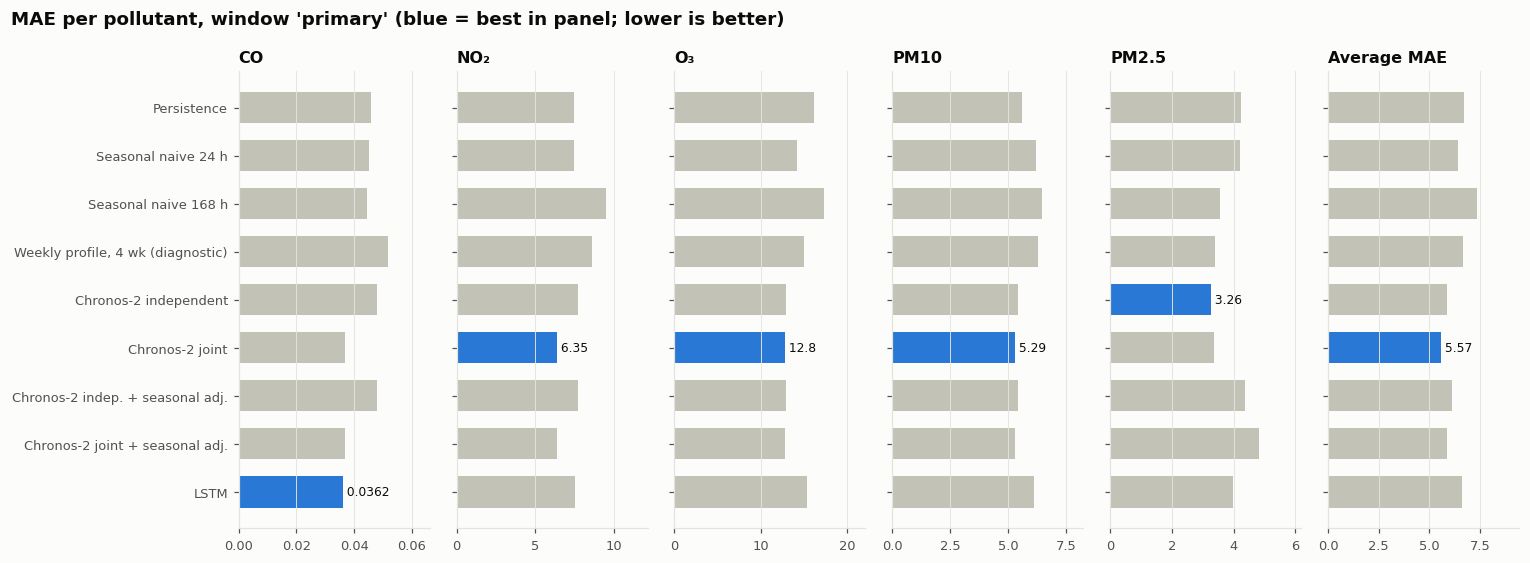

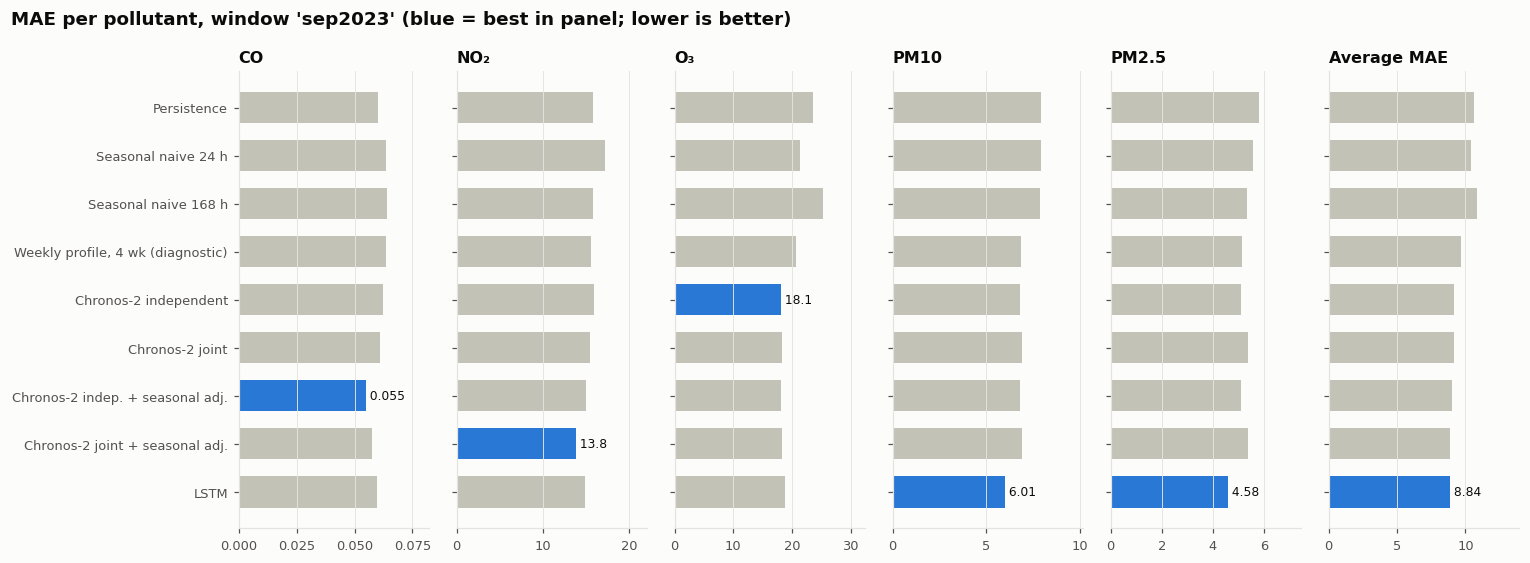

In [16]:
MODELS = BASELINES + CHRONOS + ADJUSTED + ["lstm"]
tab = mae_table(ALL_ROWS)
for w in ["primary", "sep2023"]:
    display(Markdown(f"**Window `{w}`** (MAE; lower is better)"))
    display(tab[tab.window == w].set_index("model").loc[MODELS].drop(columns="window").round(3))
    _ = plots.mae_comparison(tab, w, MODELS)
display(Markdown("**Summary: average MAE per window and spread over the rolling folds**"))
SUMMARY = summarize(ALL_ROWS).loc[MODELS]
display(SUMMARY.round(3))
best_per = {w: tab[(tab.window == w) & tab.model.isin(MODELS)].set_index("model")[[SHORT[c] for c in TARGETS] + ["avg_MAE"]].idxmin()
            for w in ["primary", "sep2023"]}
display(Markdown("**Best model per pollutant:**"))
display(pd.DataFrame(best_per))

### 6.2 Does the error grow over the 504-hour horizon?
MAE for week 1, week 2 and week 3 of the window.

**`primary`**

block     CO    NO2      O3   PM10   PM25
model                                                              
persistence         0    h1-168  0.026  6.615  14.373  6.223  4.436
                    1  h169-336  0.040  8.339  17.337  5.000  4.129
                    2  h337-504  0.071  7.359  16.770  5.705  4.137
seasonal_naive_168h 0    h1-168  0.034  9.277  17.798  4.075  2.854
                    1  h169-336  0.039  9.428  17.639  6.740  2.341
                    2  h337-504  0.060  9.845  16.473  7.715  5.610
chronos2_joint      0    h1-168  0.024  4.940  12.077  4.638  2.830
                    1  h169-336  0.031  7.024  12.616  4.540  2.909
                    2  h337-504  0.055  7.596  13.678  6.250  4.458
lstm                0    h1-168  0.032  6.481  17.040  7.424  4.582
                    1  h169-336  0.029  7.709  14.335  6.306  3.566
                    2  h337-504  0.048  8.817  14.768  5.211  3.794

**`sep2023`**

block     CO     NO2      O3    PM10    PM25
model                                                                 
persistence         0    h1-168  0.108  25.638  35.846  16.274  10.527
                    1  h169-336  0.037  12.783  21.542   8.640   5.130
                    2  h337-504  0.035   8.998  13.176   3.957   1.801
seasonal_naive_168h 0    h1-168  0.107  24.247  33.588  13.671   9.547
                    1  h169-336  0.045  13.962  26.301   7.422   4.311
                    2  h337-504  0.040   9.069  16.148   5.823   2.107
chronos2_joint      0    h1-168  0.115  25.937  27.702  15.191   9.886
                    1  h169-336  0.038  12.832  17.589   7.065   4.481
                    2  h337-504  0.030   7.497   9.374   3.389   1.713
lstm                0    h1-168  0.113  24.665  28.710  10.479   7.787
                    1  h169-336  0.037  12.002  17.997   4.801   2.788
                    2  h337-504  0.030   7.731   9.439   5.030   3.161

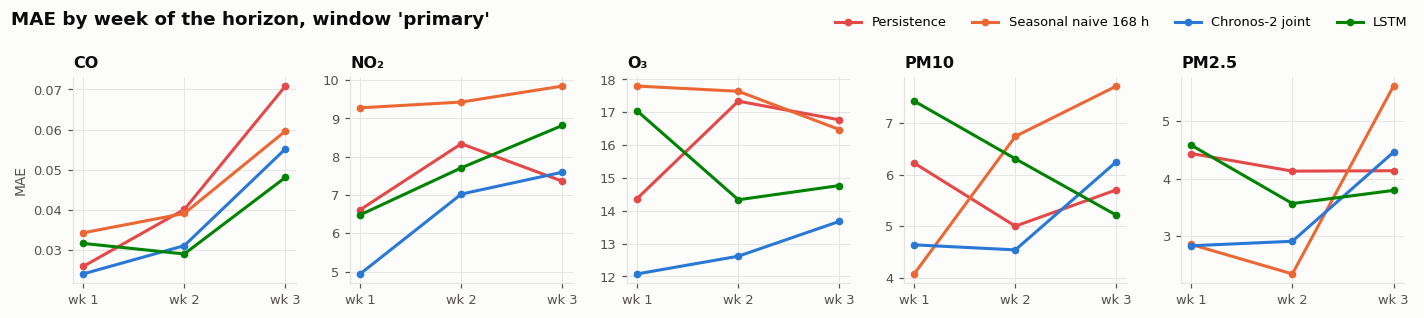

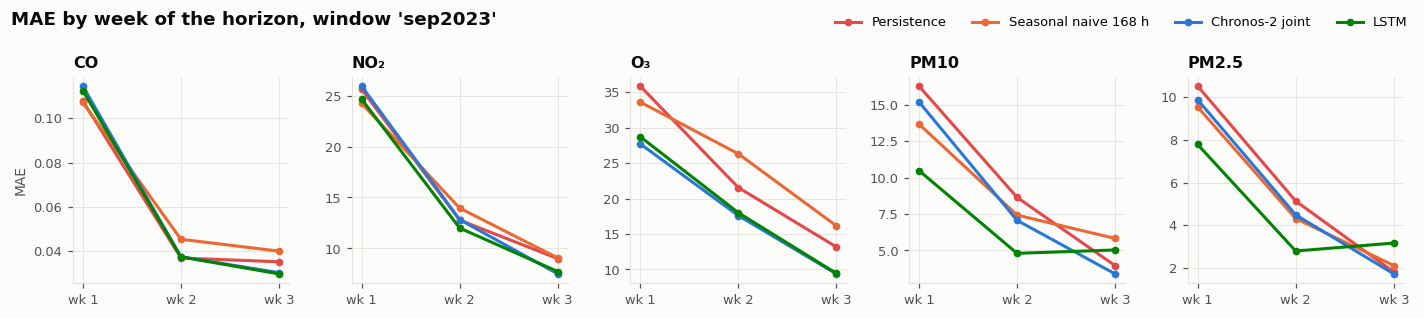

In [17]:
for w in ["primary", "sep2023"]:
    truth = windows[w][1]
    blocks = {m: mae_by_horizon_block(truth, PREDS[(m, w)]) for m in
              ["persistence", "seasonal_naive_168h", "chronos2_joint", "lstm"]}
    display(Markdown(f"**`{w}`**"))
    display(pd.concat(blocks, names=["model"]).round(3))
    _ = plots.horizon_profile(blocks, f"results_horizon_{w}", f"MAE by week of the horizon, window '{w}'")

### 6.3 Observed vs predicted

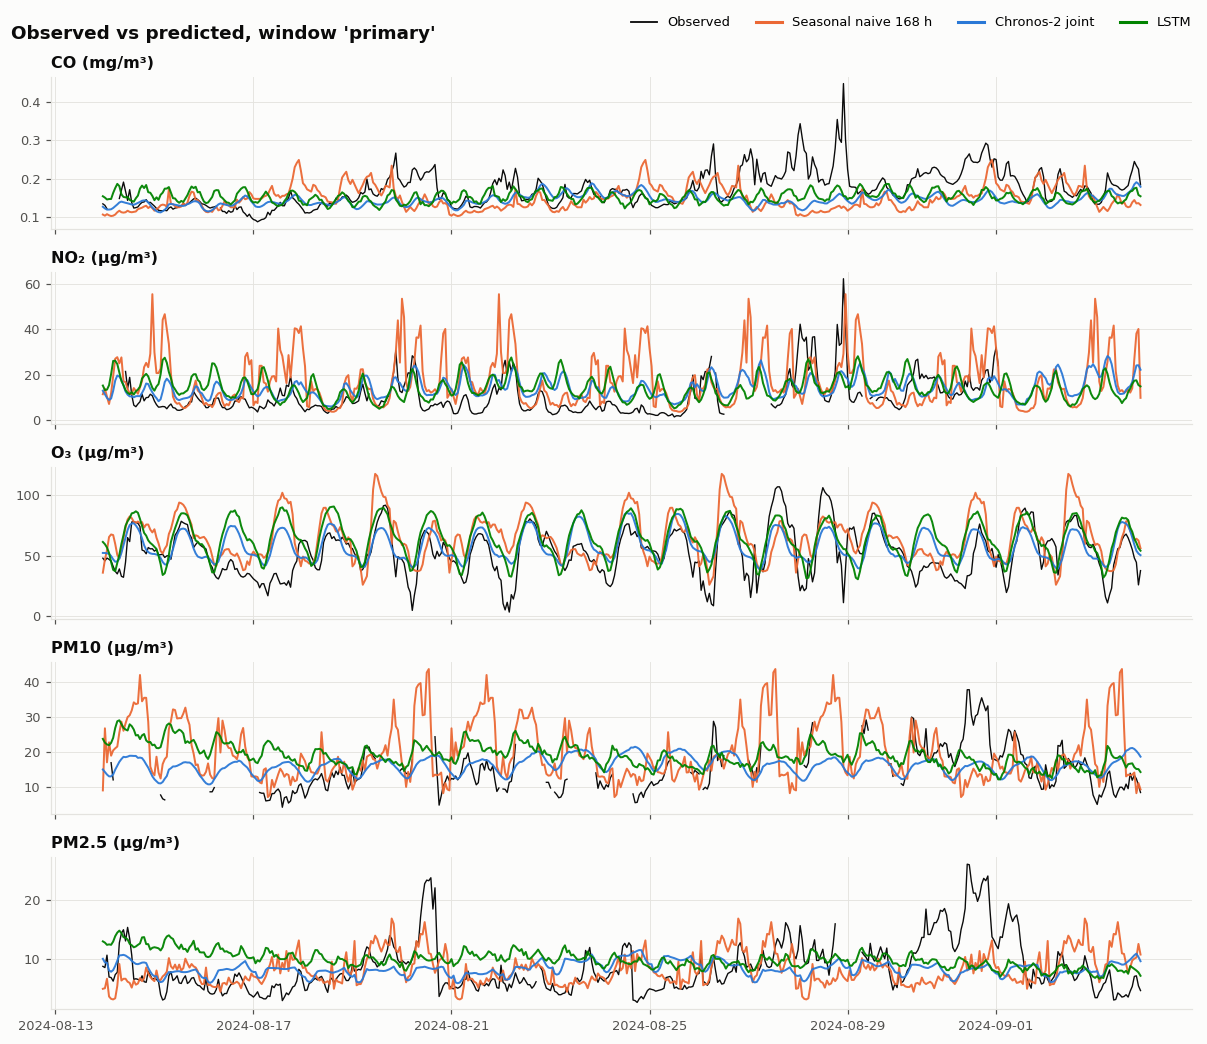

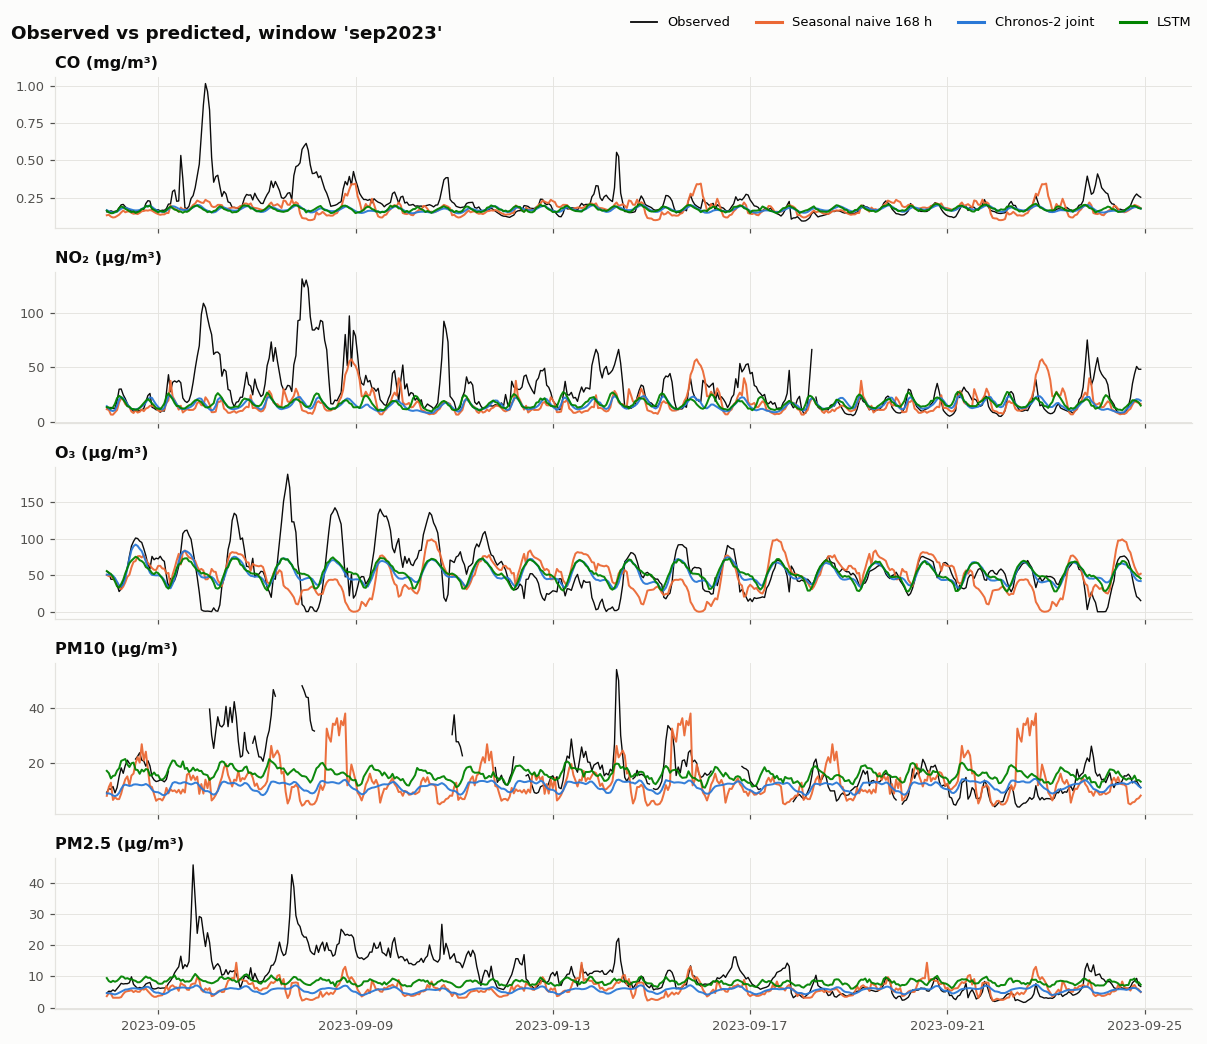

In [18]:
for w in ["primary", "sep2023"]:
    _ = plots.observed_vs_predicted(windows[w][1],
        {m: PREDS[(m, w)] for m in ["seasonal_naive_168h", "chronos2_joint", "lstm"]},
        f"results_obs_pred_{w}", f"Observed vs predicted, window '{w}'")

## 7. Final forecast and submission

**Selection rule:** the model with the lowest average MAE on `sep2023`, the window that matches the
test season (fixed before the LSTM and the seasonal fix were scored; see section 2). For the LSTM,
the mean over its three seeds is used, since a single seed is not a stable estimate. The
competition's leaderboard scores are never used for selection.

**Tie-break (added after seeing the results, stated here for transparency):** the LSTM and
Chronos-2 joint + seasonal adjustment finished within 0.02 of each other on `sep2023`, less than
the LSTM's own seed-to-seed standard deviation on that window. A gap smaller than seed noise is
not evidence. So models within that noise band of the best are treated as tied, and ties are
broken by the **mean average MAE over the six rolling folds** — the widest evidence available.

In [19]:
sel = summarize(ALL_ROWS)["sep2023"].loc[MODELS].copy()
sel.loc["lstm"] = seeds[seeds.window == "sep2023"]["avg_MAE"].mean()
sel = sel.sort_values()
noise = seeds[seeds.window == "sep2023"]["avg_MAE"].std()       # LSTM seed-to-seed std on sep2023
tied = sel[sel <= sel.iloc[0] + noise]
rolling = summarize(ALL_ROWS)["rolling_mean"]
decision = pd.DataFrame({"sep2023 avg MAE (LSTM: 3-seed mean)": sel,
                         "tied with best": sel.index.isin(tied.index),
                         "rolling-fold mean (tie-break)": rolling.reindex(sel.index)})
display(decision.round(3))
FINAL_MODEL = rolling.reindex(tied.index).idxmin()
print(f"noise band = LSTM seed std on sep2023 = {noise:.3f}; tied: {list(tied.index)}")
print("final model:", FINAL_MODEL)

,sep2023 avg MAE (LSTM: 3-seed mean),tied with best,rolling-fold mean (tie-break)
model,,,
lstm,8.817,True,6.320
chronos2_joint+seasonal_adj,8.860,True,5.981
chronos2_independent+seasonal_adj,8.997,False,6.010
chronos2_independent,9.175,False,5.936
chronos2_joint,9.196,False,5.875
weekly_profile_4w,9.660,False,6.448
seasonal_naive_24h,10.431,False,7.525
persistence,10.625,False,7.484
seasonal_naive_168h,10.876,False,7.918


noise band = LSTM seed std on sep2023 = 0.076; tied: ['lstm', 'chronos2_joint+seasonal_adj']
final model: chronos2_joint+seasonal_adj


In [20]:
FACTORIES = {
    "persistence": lambda: LastValue(),
    "seasonal_naive_24h": lambda: SeasonalNaive(24),
    "seasonal_naive_168h": lambda: SeasonalNaive(168),
    "weekly_profile_4w": lambda: SeasonalMean(lookback_days=28),
    "chronos2_independent": lambda: Chronos2Forecaster(mode="independent"),
    "chronos2_joint": lambda: Chronos2Forecaster(mode="joint"),
    "chronos2_independent+seasonal_adj": lambda: SeasonallyAdjusted(Chronos2Forecaster(mode="independent")),
    "chronos2_joint+seasonal_adj": lambda: SeasonallyAdjusted(Chronos2Forecaster(mode="joint")),
    "lstm": lambda: LSTMForecaster(seed=42),
}
final = FACTORIES[FINAL_MODEL]().fit(train)          # all of train = history before the test origin
test_pred = final.predict(test)
test_pred["id"] = test["id"].to_numpy()
out_path = PROJECT_DIR / "submissions" / f"final_{FINAL_MODEL.replace('+', '_')}.csv"
submission = make_submission(test_pred, sample, out_path)

# Format checks required by the assignment
written = pd.read_csv(out_path)
checks = {
    "columns identical to sample, same order": list(written.columns) == list(sample.columns[:6]),
    "ids identical to sample, same order": written["id"].equals(sample["id"]),
    "504 rows": len(written) == 504,
    "no missing predictions": int(written.isna().sum().sum()) == 0,
    "no negative concentrations": bool((written.iloc[:, 1:] >= 0).all().all()),
}
display(pd.Series(checks, name="check"))
assert all(checks.values())
print("wrote", out_path.relative_to(PROJECT_DIR))
display(written.head())

,check
"columns identical to sample, same order",True
"ids identical to sample, same order",True
504 rows,True
no missing predictions,True
no negative concentrations,True


wrote submissions/final_chronos2_joint_seasonal_adj.csv


,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
0,2024-09-03 23,21.601578,0.215787,41.805740,8.953563,4.923683
1,2024-09-04 00,19.719597,0.203750,41.991302,8.960044,5.056275
2,2024-09-04 01,17.731704,0.197840,40.902065,8.704509,5.359439
3,2024-09-04 02,17.752494,0.195030,39.716370,8.440186,4.754160
4,2024-09-04 03,19.011009,0.196420,37.327644,8.431598,4.604549


In [21]:
log_results(ALL_ROWS + seed_rows)   # results/leaderboard_local.csv
print("results logged:", len(ALL_ROWS) + len(seed_rows), "rows")

results logged: 76 rows


## 8. Limitations (expanded in the report)
- **Data:** long sensor outages (CO in 2021, NO₂ right before the test origin) mean every model
  starts NO₂ from stale information, and only four earlier Septembers exist to learn the
  post-holiday rebound from.
- **Evaluation:** one 504 h window is a small sample with strong autocorrelation, so differences
  of a few percent between models are within the fold-to-fold spread. The selection window was
  chosen after noticing the September shift, and the seasonal fix was designed after seeing it.
- **Model:** Chronos-2's context (8,192 h) cannot reach the previous year's same season, and
  zero-shot means it cannot learn location-specific calendar effects; no weather information is
  used, which drives particles and ozone.